# TP 2: Procesamiento de archivos PDF
Lucas Ponce · Procesamiento del Habla

**Selección del PDF:**
Se trabaja con el *Anuario de Estadística Forestal, edición 2024*, publicado en el sitio oficial de Argentina. El objetivo es descargarlo, revisar su estructura, extraer una tabla y analizar las palabras de una página narrativa.

El notebook se ejecuta de arriba hacia abajo en Colab. Descarga el PDF público y guarda las salidas en una carpeta local de la sesión; no requiere Drive ni archivos privados.

## 1. Preparación

Se instalan las bibliotecas que correspondan.

In [ ]:
import importlib.util
import subprocess
import sys

paquetes = {'fitz': 'PyMuPDF', 'pdfplumber': 'pdfplumber', 'spacy': 'spacy',
            'requests': 'requests', 'pandas': 'pandas', 'matplotlib': 'matplotlib'}
faltantes = [paquete for modulo, paquete in paquetes.items()
             if importlib.util.find_spec(modulo) is None]
if faltantes:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', *faltantes])
else:
    print('Las bibliotecas necesarias ya están disponibles.')

In [ ]:
from pathlib import Path
from collections import Counter
import hashlib
import json
import re
import unicodedata
import requests
import fitz  # PyMuPDF
import pdfplumber
import pandas as pd
import matplotlib.pyplot as plt
import spacy
from IPython.display import display, Image

salidas = Path('salidas_habla_tp2')
salidas.mkdir(exist_ok=True)
print('PyMuPDF:', fitz.VersionBind)
print('pdfplumber:', pdfplumber.__version__)
print('spaCy:', spacy.__version__)
%matplotlib inline

PyMuPDF: 1.28.2
pdfplumber: 0.11.10
spaCy: 3.8.16


## 2. Descarga y metadatos

Se comprueba el estado HTTP y la firma del archivo antes de guardarlo. Se informa el hash para identificar exactamente la versión analizada.

In [ ]:
url_pdf = 'https://www.argentina.gob.ar/sites/default/files/2025/07/anuario-estadistica-forestal_edicion_2024.pdf'
ruta_pdf = salidas / 'anuario-estadistica-forestal_edicion_2024.pdf'
respuesta = requests.get(url_pdf, timeout=90)
respuesta.raise_for_status()
if not respuesta.content.lstrip().startswith(b'%PDF-'):
    raise ValueError('La respuesta no comienza con una firma PDF válida.')
ruta_pdf.write_bytes(respuesta.content)
hash_pdf = hashlib.sha256(respuesta.content).hexdigest()
print('Estado HTTP:', respuesta.status_code)
print('Bytes descargados:', len(respuesta.content))
print('SHA-256:', hash_pdf)

documento = fitz.open(ruta_pdf)
if documento.needs_pass:
    raise ValueError('El PDF requiere contraseña.')
print('Páginas:', len(documento))

Estado HTTP: 200
Bytes descargados: 5841911
SHA-256: 4b11611d517d1558ee36b5ff989ce8e92dbc66e04d1822fe65f6fb22b128fdd4
Páginas: 165


In [ ]:
metadatos = documento.metadata
resumen_metadatos = pd.DataFrame({
    'Campo': ['Título', 'Autor', 'Número de páginas', 'Software creador (creator)',
              'Productor del PDF (producer)', 'Fecha de creación', 'Fecha de modificación'],
    'Valor': [metadatos.get('title') or 'No informado',
              metadatos.get('author') or 'No informado', len(documento),
              metadatos.get('creator') or 'No informado',
              metadatos.get('producer') or 'No informado',
              metadatos.get('creationDate') or 'No informada',
              metadatos.get('modDate') or 'No informada']
})
display(resumen_metadatos)
(salidas / 'metadatos.json').write_text(
    json.dumps(metadatos, ensure_ascii=False, indent=2), encoding='utf-8')

,Campo,Valor
0,Título,No informado
1,Autor,No informado
2,Número de páginas,165
3,Software creador (creator),No informado
4,Productor del PDF (producer),iLovePDF
5,Fecha de creación,No informada
6,Fecha de modificación,D:20241213142558Z


229

**Observación:** el archivo tiene 165 páginas. Los campos título, autor y creador están vacíos: no se pueden completar como si fueran metadatos originales. El productor informado es **iLovePDF**; no demuestra cuál fue el programa de autoría del documento.

En la portada se lee “Anuario de Estadística Forestal, edición 2024” y aparecen la Secretaría de Turismo, Ambiente y Deportes y la Subsecretaría de Ambiente. Esa identificación visible se distingue del campo `author`, que está vacío. La edición 2024 incluye estadísticas referidas a 2023; edición, período de los datos y fecha técnica del archivo no son lo mismo.

## 3. Texto crudo y separadores

`pagina.get_text("text", sort=False)` devuelve el texto extraído por PyMuPDF sin aplicar nuestra limpieza. No son los bytes internos del PDF. `repr()` permite ver los caracteres de control que la impresión normal oculta.

In [ ]:
textos_paginas = [pagina.get_text('text', sort=False) for pagina in documento]
if not any(texto.strip() for texto in textos_paginas):
    raise ValueError('No se encontró texto extraíble; haría falta revisar otro PDF u OCR.')

# Página física 11: página impresa 10, sección Presentación.
numero_pagina_texto = 11
texto_crudo = textos_paginas[numero_pagina_texto - 1]
print(texto_crudo)
print('Representación con separadores visibles:')
print(repr(texto_crudo))

# El JSON conserva por separado el texto de cada página.
(salidas / 'texto_crudo_por_pagina.json').write_text(
    json.dumps(textos_paginas, ensure_ascii=False, indent=2), encoding='utf-8')
# Estos marcadores de página los agregamos nosotros; no son caracteres detectados.
(salidas / 'texto_completo.txt').write_text(
    '\n\f\n'.join(textos_paginas), encoding='utf-8')

 
 
10 
 
Presentación 
El Programa Nacional de Estadística Forestal de la Dirección de Bosques, perteneciente al 
Subsecretaría de Ambiente, presenta el Anuario de Estadística Forestal desde el año 2000, en 
formato digital y virtual, brindando información sobre la producción primaria del bosque 
nativo y características de las industrias que utilizan dicha madera. Este Anuario incluye un 
análisis del comercio exterior de productos forestales exportados e importados de especies 
nativas y cultivadas, con un análisis específico para los rubros correspondientes a madera, 
pastas de madera y papel y cartón. Por su parte las Estadísticas de Incendios Forestales son 
producidas y difundidas por el programa desde el año 1993, e incluidas en el último capítulo. 
El Programa continúa trabajando en el mejoramiento del Sistema de Información Forestal 
con el fin de difundir datos útiles para todos los sectores involucrados (Servicios Forestales 
Provinciales, Administración de Parques Nacional

304528

In [ ]:
separadores = ['\n', '\n\n', '\r', '\t', '\f']
conteos_separadores = pd.DataFrame({
    'Caracteres': [repr(s) for s in separadores],
    'Página 11': [texto_crudo.count(s) for s in separadores],
    'PDF completo': [sum(t.count(s) for t in textos_paginas) for s in separadores]
})
display(conteos_separadores)
print('Secuencias de dos o más espacios en la página:', len(re.findall(r' {2,}', texto_crudo)))
print('Secuencias de dos o más espacios en todo el PDF:',
      sum(len(re.findall(r' {2,}', t)) for t in textos_paginas))
print('Líneas vacías o con solo espacios en la página:',
      sum(not linea.strip() for linea in texto_crudo.splitlines()))
print('Ejemplo de línea en blanco:', repr(next(
    linea for linea in texto_crudo.splitlines(keepends=True) if not linea.strip())))
print('Primeros bloques de extracción:')
for bloque in documento[10].get_text('blocks')[:6]:
    print(repr(bloque[4]))

,Caracteres,Página 11,PDF completo
0,'\n',38,29857
1,'\n\n',0,0
2,'\r',0,0
3,'\t',0,0
4,'\x0c',0,0


Secuencias de dos o más espacios en la página: 0
Secuencias de dos o más espacios en todo el PDF: 4484
Líneas vacías o con solo espacios en la página: 11
Ejemplo de línea en blanco: ' \n'
Primeros bloques de extracción:
' \n \n'
'10 \n \n'
'Presentación \n'
'El Programa Nacional de Estadística Forestal de la Dirección de Bosques, perteneciente al \n'
'Subsecretaría de Ambiente, presenta el Anuario de Estadística Forestal desde el año 2000, en \n'
'formato digital y virtual, brindando información sobre la producción primaria del bosque \n'


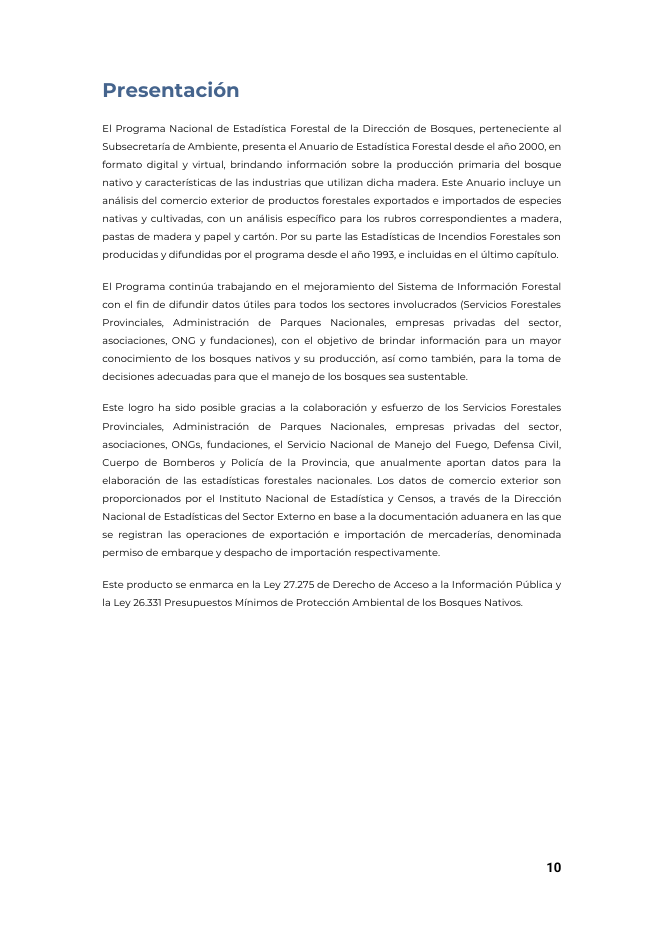

In [ ]:
# Vista de la página elegida: permite contrastar texto extraído y disposición visual.
pagina_narrativa = documento[numero_pagina_texto - 1]
pixmapa = pagina_narrativa.get_pixmap(matrix=fitz.Matrix(1.1, 1.1))
display(Image(data=pixmapa.tobytes('png')))

**Análisis:** en la página 11 se observan cuatro párrafos narrativos, el título “Presentación” y el número impreso 10. No hay tabla ni gráfico. La extracción contiene **38 saltos `\n`**; no contiene `\r`, `\t`, `\f` ni la secuencia literal `\n\n`. Hay líneas de aspecto vacío que son en realidad un espacio seguido de salto (`' \n'`).

Los saltos suelen terminar renglones, no necesariamente párrafos. En este archivo, algunos bloques de PyMuPDF también corresponden a renglones: no deben tomarse automáticamente como párrafos completos. El orden extraído ubica el número de página antes del título, aunque visualmente está al pie.

Las secciones y los capítulos se reconocen por títulos, numeración, espacio visual y cambios de página; no se detecta un carácter exclusivo que marque cada nivel. Por eso se conservan los límites de página y no se reconstruyen párrafos usando solamente `split("\n\n")`. Los `\f` del TXT exportado son marcadores agregados por este notebook, no hallazgos del PDF.

## 4. Extracción de una tabla

Se usa la primera tabla de la página física 35 (impresa 34), titulada “Extracción de productos forestales por año: 2017–2023”. Las cantidades están en toneladas (`tn`). Los valores se obtienen del PDF, sin copiar las cifras a mano.

Tabla cruda:
['Año', 'Rollizos', 'Leña', 'Postes', 'Carbón', 'Durmientes', 'Otros\nProductos']
['tn', None, None, None, None, None, None]
['2017\n2018\n2019\n2020\n2021\n2022\n2023', '653.348\n627.270\n548.664\n542.448\n658.347\n724.451\n615.534', '1.095.440\n934.061\n982.930\n954.062\n997.550\n903.620\n916.737', '32.017\n28.838\n32.065\n35.755\n50.814\n80.000\n44.575', '397.321\n270.205\n298.399\n276.035\n322.291\n341.271\n288.110', '18.684\n22.323\n15.444\n17.694\n21.106\n35.600\n21.700', '12.529\n9.480\n8.895\n18.093\n21.150\n11.333\n24.964']


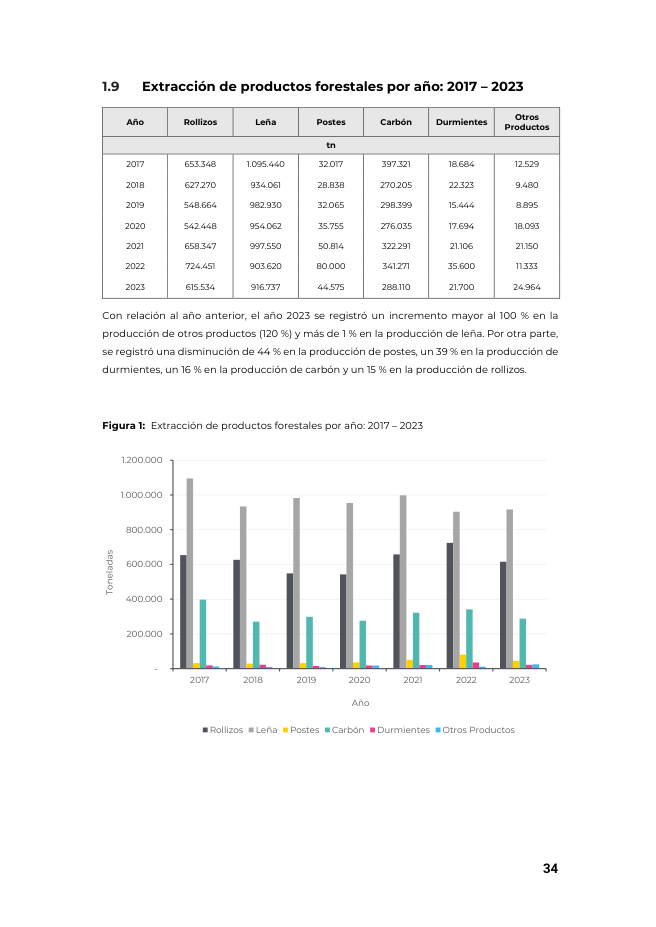

In [ ]:
numero_pagina_tabla = 35
with pdfplumber.open(ruta_pdf) as pdf_tablas:
    tablas_extraidas = pdf_tablas.pages[numero_pagina_tabla - 1].extract_tables()
if not tablas_extraidas:
    raise ValueError('No se detectaron tablas en la página elegida.')
tabla_cruda = tablas_extraidas[0]
print('Tabla cruda:')
for fila in tabla_cruda:
    print(repr(fila))
display(Image(data=documento[34].get_pixmap(matrix=fitz.Matrix(1.1, 1.1)).tobytes('png')))

In [ ]:
def limpiar_tabla_multilinea(tabla):
    # Eliminar filas completamente vacías y normalizar los encabezados.
    filas = [fila for fila in tabla if any(celda and celda.strip() for celda in fila)]
    encabezados = [' '.join((celda or '').split()) for celda in filas[0]]
    registros = []
    for fila in filas[1:]:
        # La fila de unidad "tn" no es un registro anual.
        primera_celda = (fila[0] or '').strip()
        anios = primera_celda.splitlines()
        if not anios or not all(re.fullmatch(r'\d{4}', anio.strip()) for anio in anios):
            continue
        columnas = [[valor.strip() for valor in (celda or '').splitlines()]
                    for celda in fila]
        if len({len(columna) for columna in columnas}) != 1:
            raise ValueError('Las celdas tienen distinta cantidad de renglones.')
        registros.extend(zip(*columnas))
    resultado = pd.DataFrame(registros, columns=encabezados)
    resultado = resultado.replace(r'^\s*$', pd.NA, regex=True).dropna(how='all')
    for columna in resultado.columns:
        # En esta tabla, el punto separa miles; no es un decimal.
        resultado[columna] = pd.to_numeric(
            resultado[columna].astype('string').str.replace('.', '', regex=False),
            errors='raise'
        ).astype('Int64')
    return resultado.reset_index(drop=True)

tabla_limpia = limpiar_tabla_multilinea(tabla_cruda)
assert tabla_limpia.shape == (7, 7)
assert tabla_limpia['Año'].tolist() == list(range(2017, 2024))
assert not tabla_limpia.isna().any().any()
assert not tabla_limpia.duplicated().any()
display(tabla_limpia)
print('Dimensión:', tabla_limpia.shape)
print('Unidades: toneladas; Año no es una cantidad en toneladas.')
tabla_limpia.to_csv(salidas / 'productos_forestales_2017_2023.csv', index=False)

,Año,Rollizos,Leña,Postes,Carbón,Durmientes,Otros Productos
0,2017,653348,1095440,32017,397321,18684,12529
1,2018,627270,934061,28838,270205,22323,9480
2,2019,548664,982930,32065,298399,15444,8895
3,2020,542448,954062,35755,276035,17694,18093
4,2021,658347,997550,50814,322291,21106,21150
5,2022,724451,903620,80000,341271,35600,11333
6,2023,615534,916737,44575,288110,21700,24964


Dimensión: (7, 7)
Unidades: toneladas; Año no es una cantidad en toneladas.


**Resultado:** la extracción inicial agrupa los siete años dentro de celdas con saltos de línea. Se separan esos renglones en siete registros y se conserva la correspondencia entre columnas. La fila “tn” se retira como unidad, no como dato perdido; “Otros\nProductos” se convierte en “Otros Productos”. Se eliminan filas completamente vacías y se validan dimensiones, años y nulos.

Los puntos de esta tabla son separadores de miles: por ejemplo, `653.348` se interpreta como 653348 toneladas. La misma regla no debe aplicarse sin revisar una tabla con decimales. El resultado tiene siete filas y siete columnas numéricas, listo para analizarse con Pandas.

## 5. Limpieza y frecuencias de la página narrativa

Se analiza únicamente la página 11, no todo el informe. `spacy.blank("es")` aporta tokenización y palabras vacías del español; no se requiere un modelo entrenado. Se pasan los caracteres a minúsculas, se conservan solo tokens alfabéticos y se eliminan las stop words. Las tildes se conservan. No se lematiza: singular y plural siguen siendo palabras distintas.

In [ ]:
nlp = spacy.blank('es')
texto_minusculas = unicodedata.normalize('NFC', texto_crudo.lower())
tokens_spacy = nlp(texto_minusculas)
tokens_alfabeticos = [token.text for token in tokens_spacy if token.is_alpha]
tokens_limpios = [token.text for token in tokens_spacy if token.is_alpha and not token.is_stop]
frecuencias = Counter(tokens_limpios)
# Orden alfabético en los empates, para que el top sea reproducible.
top15 = pd.DataFrame(sorted(frecuencias.items(), key=lambda x: (-x[1], x[0]))[:15],
                     columns=['palabra', 'frecuencia'])
print('Tokens alfabéticos:', len(tokens_alfabeticos))
print('Tokens después de quitar stop words:', len(tokens_limpios))
print('Palabras distintas:', len(frecuencias))
display(top15)
top15.to_csv(salidas / 'top15_palabras.csv', index=False)

Tokens alfabéticos: 320
Tokens después de quitar stop words: 170
Palabras distintas: 122


,palabra,frecuencia
0,forestales,5
1,bosques,4
2,información,4
3,nacional,4
4,datos,3
5,estadística,3
6,estadísticas,3
7,forestal,3
8,madera,3
9,nacionales,3


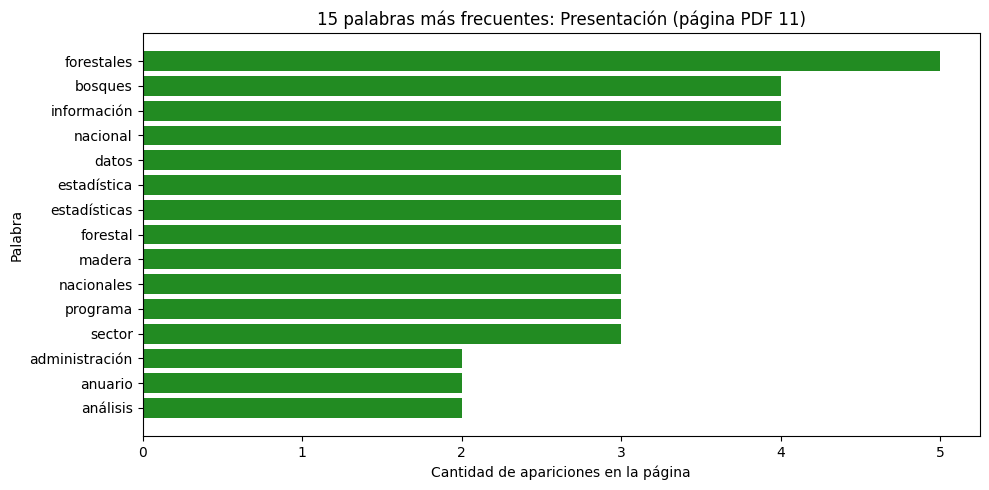

In [ ]:
def graficar_top(tabla, titulo, archivo):
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.barh(tabla['palabra'][::-1], tabla['frecuencia'][::-1], color='forestgreen')
    ax.set_title(titulo)
    ax.set_xlabel('Cantidad de apariciones en la página')
    ax.set_ylabel('Palabra')
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    fig.tight_layout()
    fig.savefig(salidas / archivo, dpi=160, bbox_inches='tight')
    plt.show()

graficar_top(top15, '15 palabras más frecuentes: Presentación (página PDF 11)',
             'top15_palabras.png')

**Observación del gráfico:** “forestales” aparece 5 veces; “bosques”, “información” y “nacional”, 4. La página presenta el trabajo estadístico forestal y sus organismos participantes; las frecuencias son coherentes con ese contenido. Tras filtrar signos, números y stop words quedan **170 tokens**, correspondientes a **122 palabras distintas**. Hay empates en la frecuencia 2: se resuelven alfabéticamente para elegir quince palabras.

**Stop words adicionales:** en este gráfico aparecen “nacional”, “nacionales”, “programa” y “administración”. Para una segunda vista centrada en el contenido forestal, pueden tratarse como palabras vacías de contexto: describen el encuadre institucional más que los productos o actividades. Se retirarán solo en una comparación adicional, manteniendo el primer resultado. Si el objetivo fuera estudiar los organismos responsables, sería correcto conservarlas. No se eliminan automáticamente “datos”, “información” ni “estadística”, porque sí son centrales para el propósito del documento.

Palabras retiradas en la comparación:
administración : 2
nacional : 4
nacionales : 3
programa : 3


,palabra,frecuencia
0,forestales,5
1,bosques,4
2,información,4
3,datos,3
4,estadística,3
5,estadísticas,3
6,forestal,3
7,madera,3
8,sector,3
9,anuario,2


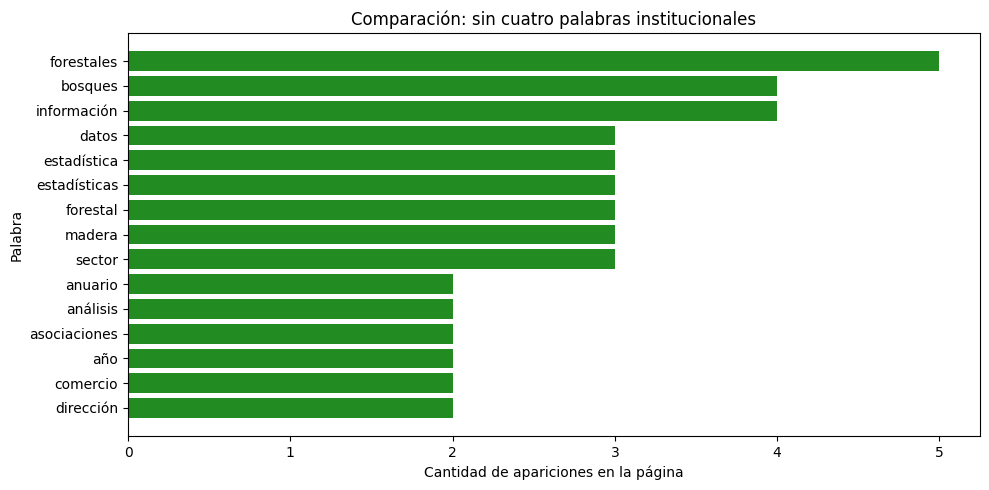

Tokens en la comparación: 158


In [ ]:
stopwords_adicionales = {'nacional', 'nacionales', 'programa', 'administración'}
print('Palabras retiradas en la comparación:')
for palabra in sorted(stopwords_adicionales):
    print(palabra, ':', frecuencias[palabra])
tokens_contexto = [t for t in tokens_limpios if t not in stopwords_adicionales]
frecuencias_contexto = Counter(tokens_contexto)
top15_contexto = pd.DataFrame(
    sorted(frecuencias_contexto.items(), key=lambda x: (-x[1], x[0]))[:15],
    columns=['palabra', 'frecuencia']
)
display(top15_contexto)
graficar_top(top15_contexto, 'Comparación: sin cuatro palabras institucionales',
             'top15_contexto.png')
top15_contexto.to_csv(salidas / 'top15_contexto.csv', index=False)
(salidas / 'texto_limpio_pagina11.txt').write_text(' '.join(tokens_limpios), encoding='utf-8')
print('Tokens en la comparación:', len(tokens_contexto))

La lista adicional elimina **12 apariciones** y deja **158 tokens**. Es una decisión del análisis, no un error de spaCy. Se conservan ambos gráficos para que el efecto sea visible. Como no se lematizó, “forestal”/“forestales” y “estadística”/“estadísticas” se cuentan por separado; unirlas sería otra transformación que debería justificarse.

In [ ]:
validacion = {
    'url': url_pdf, 'sha256': hash_pdf, 'paginas': len(documento),
    'pagina_texto_pdf': numero_pagina_texto, 'pagina_tabla_pdf': numero_pagina_tabla,
    'tabla_filas': len(tabla_limpia), 'tabla_columnas': len(tabla_limpia.columns),
    'tokens_alfabeticos': len(tokens_alfabeticos), 'tokens_limpios': len(tokens_limpios),
    'palabras_distintas': len(frecuencias), 'tokens_contexto': len(tokens_contexto),
    'versiones': {'pymupdf': fitz.VersionBind, 'pdfplumber': pdfplumber.__version__,
                 'spacy': spacy.__version__, 'pandas': pd.__version__}
}
(salidas / 'validacion.json').write_text(
    json.dumps(validacion, ensure_ascii=False, indent=2), encoding='utf-8')
print('Salidas generadas:', sorted(p.name for p in salidas.iterdir()))
documento.close()

Salidas generadas: ['anuario-estadistica-forestal_edicion_2024.pdf', 'metadatos.json', 'productos_forestales_2017_2023.csv', 'texto_completo.txt', 'texto_crudo_por_pagina.json', 'texto_limpio_pagina11.txt', 'top15_contexto.csv', 'top15_contexto.png', 'top15_palabras.csv', 'top15_palabras.png', 'validacion.json']


## 6. Conclusiones y límites

La descarga y extracción permiten convertir un PDF en texto y una tabla reutilizable. La disposición visual no equivale a una estructura lógica de párrafos o filas: hubo que distinguir renglones, unidad de medida y celdas multilínea. Los metadatos vacíos se informan como ausentes.

La frecuencia de palabras describe esta página introductoria; no resume por sí sola todo el informe ni mide la importancia de cada concepto. El PDF puede cambiar en el sitio de origen: se registra su hash y la ejecución falla de forma explícita si desaparece la tabla esperada. La revisión del foro no encontró coincidencias identificables, pero tuvo una entrega no verificable; esa limitación debe considerarse antes de publicar.

## 7. Referencias y asistencia

- Documento analizado: [Anuario de Estadística Forestal, edición 2024](https://www.argentina.gob.ar/sites/default/files/2025/07/anuario-estadistica-forestal_edicion_2024.pdf)
- Consigna TP2 y notebooks docentes: `0_archivos_pdf.ipynb` y `UNIDAD_1_Limpieza_de_Texto_parte_1.ipynb`
- [Ejemplo docente de PDF](https://github.com/anadiedrichs/procesamientoDelHabla/blob/main/0_archivos_pdf.ipynb)
- [Ejemplo docente de limpieza](https://github.com/anadiedrichs/procesamientoDelHabla/blob/main/UNIDAD_1_Limpieza_de_Texto_parte_1.ipynb)
- [PyMuPDF: extracción de texto](https://pymupdf.readthedocs.io/en/latest/recipes-text.html)
- [pdfplumber: extracción de tablas](https://github.com/jsvine/pdfplumber#extracting-tables)
- [spaCy: tokenización y procesamiento](https://spacy.io/usage/linguistic-features#tokenization)

**Asistencia de IA:** se utilizó para preparar y revisar el código (chatgpt)


## 8. Reflexión personal

Con este trabajo aprendí a usar herramientas nuevas para extraer texto y tablas de un PDF. Lo que más me costó fue entender la limpieza y la normalización, y cómo influyen en los gráficos y en el análisis. Entendí que no alcanza con extraer los datos: también hay que revisar cómo quedaron y prepararlos antes de analizarlos. Me llevo herramientas que pueden ser útiles para otros trabajos.

Pasar el texto a minúsculas evita que una misma palabra se cuente por separado por estar escrita con mayúscula o minúscula. Comparar el texto extraído con el PDF permite revisar si se conserva el orden y cómo quedó organizado. También entendí que una palabra aparezca más veces no significa necesariamente que sea más importante.

**Enlace del video:** https://drive.google.com/file/d/1pXkPNYPxabcHCIad5IYpqt4bp8U14Q4q/view?usp=sharing
